In [ ]:
pip install -q numpy pandas scikit-learn scipy statsmodels matplotlib

Step 3: Import libraries and load the dataset

In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.inspection import permutation_importance
from statsmodels.stats.contingency_tables import mcnemar

# Create a folder for experiment results
os.makedirs("results", exist_ok=True)

# Load the built-in dataset
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

# Create feature-based groups for demonstration
groups = np.where(
    X["mean radius"] >= X["mean radius"].median(),
    "Group B", "Group A"
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test, group_train, group_test = (
    train_test_split(
        X, y, groups,
        test_size=0.25,
        random_state=42,
        stratify=y
    )
)

print("Dataset loaded successfully.")
print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Dataset loaded successfully.
Total samples: 569
Training samples: 426
Testing samples: 143


Step 4: Perform A/B testing on two ML models

In [ ]:

# Model A: Logistic Regression
model_a = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
# Model B: Random Forest
model_b = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
# Train both models on the same training data
model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)

# Predict using the same test data
pred_a = model_a.predict(X_test)
pred_b = model_b.predict(X_test)

# Calculate performance metrics
results = []

for name, predictions in [
    ("Model A - Logistic Regression", pred_a),
    ("Model B - Random Forest", pred_b)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison = pd.DataFrame(results)

print("A/B TESTING: MODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv("results/model_comparison.csv", index=False)


A/B TESTING: MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Model A - Logistic Regression,0.986,0.9889,0.9889,0.9889
1,Model B - Random Forest,0.958,0.9565,0.9778,0.9670


Step 5: Perform statistical hypothesis testing

In [ ]:
# Compare the correctness of both models' predictions
correct_a = (pred_a == y_test.to_numpy())
correct_b = (pred_b == y_test.to_numpy())

both_correct = int(np.sum(correct_a & correct_b))
a_only_correct = int(np.sum(correct_a & ~correct_b))
b_only_correct = int(np.sum(~correct_a & correct_b))
both_wrong = int(np.sum(~correct_a & ~correct_b))

contingency_table = [
    [both_correct, a_only_correct],
    [b_only_correct, both_wrong]
]

test_result = mcnemar(contingency_table, exact=True)

alpha = 0.05

print("STATISTICAL HYPOTHESIS TESTING")
print("H0: Both models have the same error rate.")
print("H1: The models have different error rates.")
print("Significance level:", alpha)
print("McNemar test p-value:", round(test_result.pvalue, 4))

if test_result.pvalue < alpha:
    print("Decision: Reject H0.")
    print("The difference in error patterns is statistically significant.")
else:
    print("Decision: Fail to reject H0.")
    print("There is insufficient evidence of a difference.")

STATISTICAL HYPOTHESIS TESTING
H0: Both models have the same error rate.
H1: The models have different error rates.
Significance level: 0.05
McNemar test p-value: 0.2188
Decision: Fail to reject H0.
There is insufficient evidence of a difference.


Step 6: Perform model explainability

Selected model: Model A - Logistic Regression

Top 10 Important Features:


,Feature,Importance
21,worst texture,0.0280
10,radius error,0.0230
23,worst area,0.0169
13,area error,0.0159
20,worst radius,0.0157
22,worst perimeter,0.0135
26,worst concavity,0.0135
7,mean concave points,0.0125
3,mean area,0.0124
24,worst smoothness,0.0112


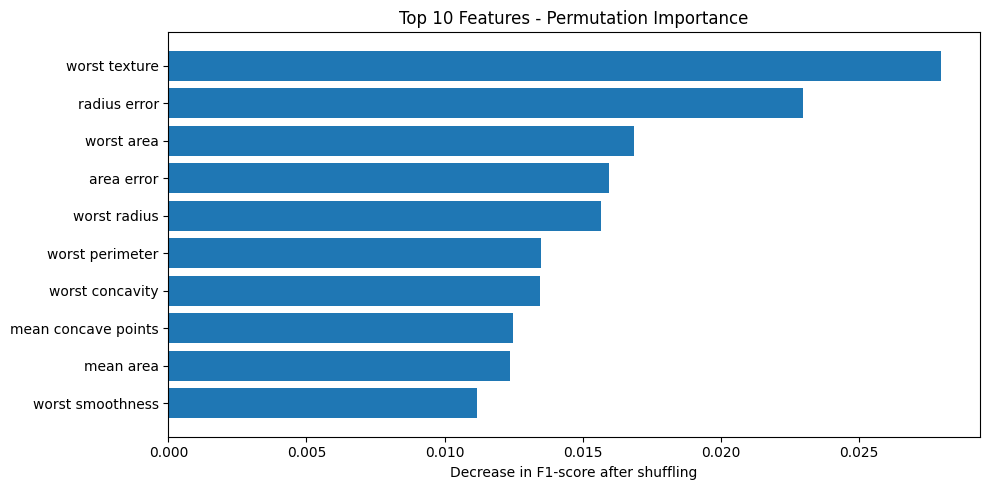

In [ ]:

# Select the model with the higher F1-score
best_index = comparison["F1 Score"].idxmax()
best_name = comparison.loc[best_index, "Model"]

best_model = (
    model_a if best_name == "Model A - Logistic Regression"
    else model_b
)

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

print("Selected model:", best_name)
print("\nTop 10 Important Features:")
display(importance_df.head(10).round(4))

importance_df.to_csv("results/feature_importance.csv", index=False)

# Plot the top 10 features
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in F1-score after shuffling")
plt.title("Top 10 Features - Permutation Importance")
plt.tight_layout()
plt.savefig("results/feature_importance.png", dpi=150)
plt.show()


Step 7: Perform subgroup fairness assessment

In [ ]:

# Compare model performance across two feature-based groups
fairness_results = []

group_values = np.asarray(group_test)
actual_values = y_test.to_numpy()

for group_name in ["Group A", "Group B"]:
    mask = group_values == group_name
    actual = actual_values[mask]

    for model_name, predictions in [
        ("Model A - Logistic Regression", pred_a),
        ("Model B - Random Forest", pred_b)
    ]:
        group_predictions = predictions[mask]

        fairness_results.append({
            "Group": group_name,
            "Model": model_name,
            "Samples": int(mask.sum()),
            "Accuracy": accuracy_score(actual, group_predictions),
            "Recall": recall_score(
                actual, group_predictions, zero_division=0
            )
        })

fairness_df = pd.DataFrame(fairness_results)

print("SUBGROUP PERFORMANCE ASSESSMENT")
display(fairness_df.round(4))

fairness_df.to_csv("results/fairness_assessment.csv", index=False)

print("Note: Feature-based subgroup comparison only.")
print("It does not establish demographic fairness or compliance.")


SUBGROUP PERFORMANCE ASSESSMENT


,Group,Model,Samples,Accuracy,Recall
0,Group A,Model A - Logistic Regression,68,1.0000,1.00
1,Group A,Model B - Random Forest,68,0.9853,1.00
2,Group B,Model A - Logistic Regression,75,0.9733,0.96
3,Group B,Model B - Random Forest,75,0.9333,0.92


Note: Feature-based subgroup comparison only.
It does not establish demographic fairness or compliance.


Step 8: Document model governance

In [ ]:

# Record important experiment details
governance = pd.DataFrame([{
    "Dataset": "Breast Cancer Wisconsin",
    "Model_A": "Logistic Regression",
    "Model_B": "Random Forest",
    "Train_Test_Split": "75% / 25%",
    "Random_State": 42,
    "Primary_Metric": "F1 Score",
    "Statistical_Test": "Exact McNemar Test",
    "Significance_Level": 0.05,
    "Explainability": "Permutation Feature Importance",
    "Fairness_Check": "Feature-based subgroup comparison"
}])

governance.to_csv("results/experiment_governance.csv", index=False)

print("MODEL GOVERNANCE RECORD")
display(governance)

print("Governance record saved successfully.")


MODEL GOVERNANCE RECORD


,Dataset,Model_A,Model_B,Train_Test_Split,Random_State,Primary_Metric,Statistical_Test,Significance_Level,Explainability,Fairness_Check
0,Breast Cancer Wisconsin,Logistic Regression,Random Forest,75% / 25%,42,F1 Score,Exact McNemar Test,0.05,Permutation Feature Importance,Feature-based subgroup comparison


Governance record saved successfully.


Step 9: Download the experiment results

In [ ]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/Assignment5_Results",
    "zip",
    "/content/results"
)

files.download("/content/Assignment5_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>